# Import libraries and locate data

In [17]:
import pandas as pd
import numpy as np
from pathlib import Path

# Locate project root
cwd = Path.cwd()

if (cwd / "data").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Project data folder not found.")

DATA_DIR = PROJECT_ROOT / "data" / "processed"

EVENT_FILE = DATA_DIR / "ehr_event_log_clean.csv"
CASE_FILE = DATA_DIR / "ehr_cases_clean.csv"

print("Project:", PROJECT_ROOT)
print("Event file exists:", EVENT_FILE.exists())
print("Case file exists:", CASE_FILE.exists())

Project: C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining
Event file exists: True
Case file exists: True


# Load event log and case data

In [18]:
if not EVENT_FILE.exists() or not CASE_FILE.exists():
    raise FileNotFoundError("Required cleaned CSV files are missing.")

events = pd.read_csv(EVENT_FILE)
cases = pd.read_csv(CASE_FILE)

print("Event Log Shape:", events.shape)
print("Case Data Shape:", cases.shape)

display(events.head())
display(cases.head())

Event Log Shape: (4875, 33)
Case Data Shape: (500, 21)


,case_id,patient_id,age,age_group,sex,region,arrival_mode,acuity,chief_complaint,diagnosis_group,...,location,wait_minutes,duration_minutes,loopback_type,is_loopback,event_status,disposition,data_source,data_version,cleaning_version
0,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-4,0,14,NaN,False,Completed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1
1,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-1,28,2,NaN,True,Completed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1
2,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-4,3,9,NaN,False,Completed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1
3,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-2,9,8,NaN,False,Delayed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1
4,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-1,5,15,NaN,False,Completed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1


,case_id,patient_id,age,age_group,sex,region,arrival_mode,acuity,chief_complaint,diagnosis_group,...,insurance_type,arrival_timestamp,hospital_site,referral_source,disposition,event_count,loopback_type,end_timestamp,length_of_stay_minutes,cleaning_version
0,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Other,2026-06-28 16:45:08,Site-A,Self,Discharged Home,11,NaN,2026-06-28 20:56:08,251,week1-v1
1,CF-0000002,PAT-0000002,43,40-64,Other/Unknown,South,Referral,High,Dizziness,Migraine,...,Self-Pay,2026-04-30 19:31:53,Site-B,Primary Care,Discharged Home,10,Repeat Doctor Assessment,2026-04-30 23:39:53,248,week1-v1
2,CF-0000003,PAT-0000003,51,40-64,Female,West,Ambulance,Low,Back Pain,Musculoskeletal Pain,...,Other,2026-08-18 18:45:53,Site-C,Other Hospital,Discharged Home,8,Reassessment to Triage,2026-08-18 21:45:53,180,week1-v1
3,CF-0000004,PAT-0000004,9,0-17,Female,North,Ambulance,Critical,Breathing Difficulty,Chest Pain Under Evaluation,...,Public,2026-04-16 18:45:29,Site-C,Emergency Services,Transferred,6,NaN,2026-04-16 20:51:29,126,week1-v1
4,CF-0000005,PAT-0000005,26,18-39,Male,East,Walk-in,Moderate,Allergic Reaction,Chest Pain Under Evaluation,...,Public,2026-08-22 14:21:18,Site-C,Primary Care,Transferred,9,NaN,2026-08-22 17:30:18,189,week1-v1


# Data structure inspection

In [19]:
print("EVENT LOG COLUMNS")
print(events.columns.tolist())

print("\nDATA TYPES")
display(events.dtypes)

print("\nMISSING VALUES")
display(events.isnull().sum())

print("\nDUPLICATE ROWS")
print(events.duplicated().sum())

EVENT LOG COLUMNS
['case_id', 'patient_id', 'age', 'age_group', 'sex', 'region', 'arrival_mode', 'acuity', 'chief_complaint', 'diagnosis_group', 'comorbidities', 'insurance_type', 'arrival_timestamp', 'hospital_site', 'referral_source', 'event_id', 'event_sequence', 'activity', 'timestamp', 'previous_activity', 'department', 'resource_id', 'resource_role', 'location', 'wait_minutes', 'duration_minutes', 'loopback_type', 'is_loopback', 'event_status', 'disposition', 'data_source', 'data_version', 'cleaning_version']

DATA TYPES


case_id                str
patient_id             str
age                  int64
age_group              str
sex                    str
region                 str
arrival_mode           str
acuity                 str
chief_complaint        str
diagnosis_group        str
comorbidities          str
insurance_type         str
arrival_timestamp      str
hospital_site          str
referral_source        str
event_id               str
event_sequence       int64
activity               str
timestamp              str
previous_activity      str
department             str
resource_id            str
resource_role          str
location               str
wait_minutes         int64
duration_minutes     int64
loopback_type          str
is_loopback           bool
event_status           str
disposition            str
data_source            str
data_version           str
cleaning_version       str
dtype: object


MISSING VALUES


case_id                 0
patient_id              0
age                     0
age_group               0
sex                     0
region                  0
arrival_mode            0
acuity                  0
chief_complaint         0
diagnosis_group         0
comorbidities         474
insurance_type          0
arrival_timestamp       0
hospital_site           0
referral_source         0
event_id                0
event_sequence          0
activity                0
timestamp               0
previous_activity     500
department              0
resource_id             0
resource_role           0
location                0
wait_minutes            0
duration_minutes        0
loopback_type        3290
is_loopback             0
event_status            0
disposition             0
data_source             0
data_version            0
cleaning_version        0
dtype: int64


DUPLICATE ROWS
0


# Initial data quality summary

In [20]:
print("Total Events:", len(events))
print("Total Cases:", len(cases))

print("Unique Event Log Values:")
display(events.nunique())

print("\nStatistical Summary:")
display(events.describe(include="all").T)

Total Events: 4875
Total Cases: 500
Unique Event Log Values:


case_id               500
patient_id            500
age                    95
age_group               4
sex                     3
region                  5
arrival_mode            4
acuity                  4
chief_complaint        12
diagnosis_group        10
comorbidities          42
insurance_type          4
arrival_timestamp     500
hospital_site           3
referral_source         4
event_id             4875
event_sequence         15
activity               14
timestamp            4875
previous_activity      13
department              4
resource_id            10
resource_role           6
location                4
wait_minutes          130
duration_minutes       65
loopback_type           3
is_loopback             2
event_status            3
disposition             4
data_source             1
data_version            1
cleaning_version        1
dtype: int64


Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
case_id,4875,500,CF-0000268,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
patient_id,4875,500,PAT-0000268,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,4875.0,NaN,NaN,NaN,46.545026,21.925653,0.0,32.0,47.0,60.0,100.0
age_group,4875,4,40-64,2130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,4875,3,Male,2566,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,4875,5,South,1108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_mode,4875,4,Walk-in,3073,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acuity,4875,4,Moderate,1813,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chief_complaint,4875,12,Allergic Reaction,499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diagnosis_group,4875,10,Chest Pain Under Evaluation,610,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Unique ID validation

In [21]:
# Event ID validation
print("Unique event IDs:", events["event_id"].nunique())
print("Total event records:", len(events))

print("Duplicate event IDs:",
      events["event_id"].duplicated().sum())

# Case ID validation
print("Unique cases:", events["case_id"].nunique())

print("Missing event IDs:",
      events["event_id"].isna().sum())

print("Missing case IDs:",
      events["case_id"].isna().sum())

Unique event IDs: 4875
Total event records: 4875
Duplicate event IDs: 0
Unique cases: 500
Missing event IDs: 0
Missing case IDs: 0


# Timestamp validation

In [22]:
events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    errors="coerce"
)

print("Invalid timestamps:",
      events["timestamp"].isna().sum())

print("Earliest event:",
      events["timestamp"].min())

print("Latest event:",
      events["timestamp"].max())

Invalid timestamps: 0
Earliest event: 2026-01-01 00:00:20
Latest event: 2026-10-01 02:46:16


# First event validation

In [23]:
events_sorted = events.sort_values(
    ["case_id", "event_sequence", "timestamp"]
).copy()

first_events = events_sorted.groupby(
    "case_id"
).head(1)

last_events = events_sorted.groupby(
    "case_id"
).tail(1)

print("First events:", len(first_events))
print("Last events:", len(last_events))

print("First events with missing previous_activity:",
      first_events["previous_activity"].isna().sum())

print("Other events with missing previous_activity:",
      events_sorted.groupby("case_id")
      .apply(lambda x: x.iloc[1:]["previous_activity"].isna().sum(),
             include_groups=False).sum())

First events: 500
Last events: 500
First events with missing previous_activity: 500
Other events with missing previous_activity: 0


# Activity distribution

In [24]:
activity_distribution = (
    events["activity"]
    .value_counts()
    .reset_index()
)

activity_distribution.columns = [
    "Activity",
    "Event_Count"
]

display(activity_distribution)

,Activity,Event_Count
0,Triage,579
1,Doctor Assessment,574
2,Registration,500
3,Treatment,500
4,Discharge Preparation,500
5,Discharge,500
6,Lab Order,373
7,Lab Sample Collection,373
8,Lab Result,373
9,Imaging Order,196


# Events per case

In [25]:
case_event_counts = (
    events.groupby("case_id")
    .size()
    .reset_index(name="event_count")
)

print("Minimum events per case:",
      case_event_counts["event_count"].min())

print("Maximum events per case:",
      case_event_counts["event_count"].max())

print("Average events per case:",
      round(case_event_counts["event_count"].mean(), 2))

display(case_event_counts.head(10))

Minimum events per case: 6
Maximum events per case: 15
Average events per case: 9.75


,case_id,event_count
0,CF-0000001,11
1,CF-0000002,10
2,CF-0000003,8
3,CF-0000004,6
4,CF-0000005,9
5,CF-0000006,10
6,CF-0000007,10
7,CF-0000008,9
8,CF-0000009,9
9,CF-0000010,11


# Prepare event log for PM4Py

In [26]:
import pm4py
from pathlib import Path

# Preserve original data
process_df = events.copy()

# Ensure correct timestamp format
process_df["timestamp"] = pd.to_datetime(
    process_df["timestamp"],
    errors="coerce"
)

# Sort events in process execution order
process_df = process_df.sort_values(
    ["case_id", "event_sequence", "timestamp"]
).reset_index(drop=True)

# Convert to PM4Py event log
event_log = pm4py.format_dataframe(
    process_df,
    case_id="case_id",
    activity_key="activity",
    timestamp_key="timestamp"
)

print("PM4Py Event Log Ready")
print("Total Events:", len(event_log))
print("Unique Cases:", event_log["case:concept:name"].nunique())
print("Activities:", event_log["concept:name"].nunique())

PM4Py Event Log Ready
Total Events: 4875
Unique Cases: 500
Activities: 14


# Process Discovery (DFG)

In [27]:
dfg, start_activities, end_activities = pm4py.discover_dfg(
    event_log
)

print("Directly-Follows Graph discovered")

print("\nStart Activities:")
print(start_activities)

print("\nEnd Activities:")
print(end_activities)

print("\nTotal Transitions:", len(dfg))

Directly-Follows Graph discovered

Start Activities:
{'Registration': 500}

End Activities:
{'Discharge': 500}

Total Transitions: 23


# Transition frequency analysis

In [28]:
transition_df = pd.DataFrame(
    [
        {
            "source_activity": source,
            "target_activity": target,
            "frequency": frequency
        }
        for (source, target), frequency in dfg.items()
    ]
)

transition_df = transition_df.sort_values(
    "frequency",
    ascending=False
).reset_index(drop=True)

display(transition_df)

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

transition_df.to_csv(
    OUTPUT_DIR / "careflow_process_edges.csv",
    index=False
)

,source_activity,target_activity,frequency
0,Triage,Doctor Assessment,509
1,Registration,Triage,500
2,Discharge Preparation,Discharge,500
3,Lab Sample Collection,Lab Result,373
4,Lab Order,Lab Sample Collection,373
5,Doctor Assessment,Lab Order,373
6,Treatment,Discharge Preparation,309
7,Lab Result,Treatment,226
8,Imaging Order,Imaging,196
9,Imaging,Treatment,196


# Process variants analysis

In [29]:
case_sequences = (
    process_df.groupby("case_id")["activity"]
    .agg(tuple)
)

variant_counts = (
    case_sequences.value_counts()
    .reset_index()
)

variant_counts.columns = [
    "activity_sequence",
    "case_count"
]

variant_counts["variant_id"] = [
    f"V{i:03d}" for i in range(1, len(variant_counts) + 1)
]

variant_counts["activity_sequence"] = (
    variant_counts["activity_sequence"]
    .apply(lambda x: " → ".join(x))
)

variant_counts["percentage"] = (
    variant_counts["case_count"] / len(case_sequences) * 100
).round(2)

variant_counts = variant_counts[
    ["variant_id", "activity_sequence", "case_count", "percentage"]
]

print("Total Unique Variants:", len(variant_counts))

display(variant_counts.head(15))

variant_counts.to_csv(
    OUTPUT_DIR / "careflow_process_variants.csv",
    index=False
)

Total Unique Variants: 25


,variant_id,activity_sequence,case_count,percentage
0,V001,Registration → Triage → Doctor Assessment → La...,146,29.2
1,V002,Registration → Triage → Doctor Assessment → La...,86,17.2
2,V003,Registration → Triage → Doctor Assessment → Tr...,52,10.4
3,V004,Registration → Triage → Doctor Assessment → Im...,25,5.0
4,V005,Registration → Triage → Doctor Assessment → La...,24,4.8
5,V006,Registration → Triage → Doctor Assessment → La...,24,4.8
6,V007,Registration → Triage → Doctor Assessment → La...,21,4.2
7,V008,Registration → Triage → Doctor Assessment → La...,19,3.8
8,V009,Registration → Triage → Doctor Assessment → La...,16,3.2
9,V010,Registration → Triage → Doctor Assessment → La...,16,3.2


# Generate As-Is Process Map

In [36]:
from pm4py.visualization.dfg import visualizer as dfg_visualizer

parameters = {
    dfg_visualizer.Variants.FREQUENCY.value.Parameters.FORMAT: "png"
}

gviz = dfg_visualizer.apply(
    dfg,
    log=event_log,
    variant=dfg_visualizer.Variants.FREQUENCY,
    parameters=parameters
)

process_map_path = OUTPUT_DIR / "careflow_as_is_process_map.png"

dfg_visualizer.save(
    gviz,
    str(process_map_path)
)

print("Process map saved:", process_map_path)

ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

# As-Is Process Map

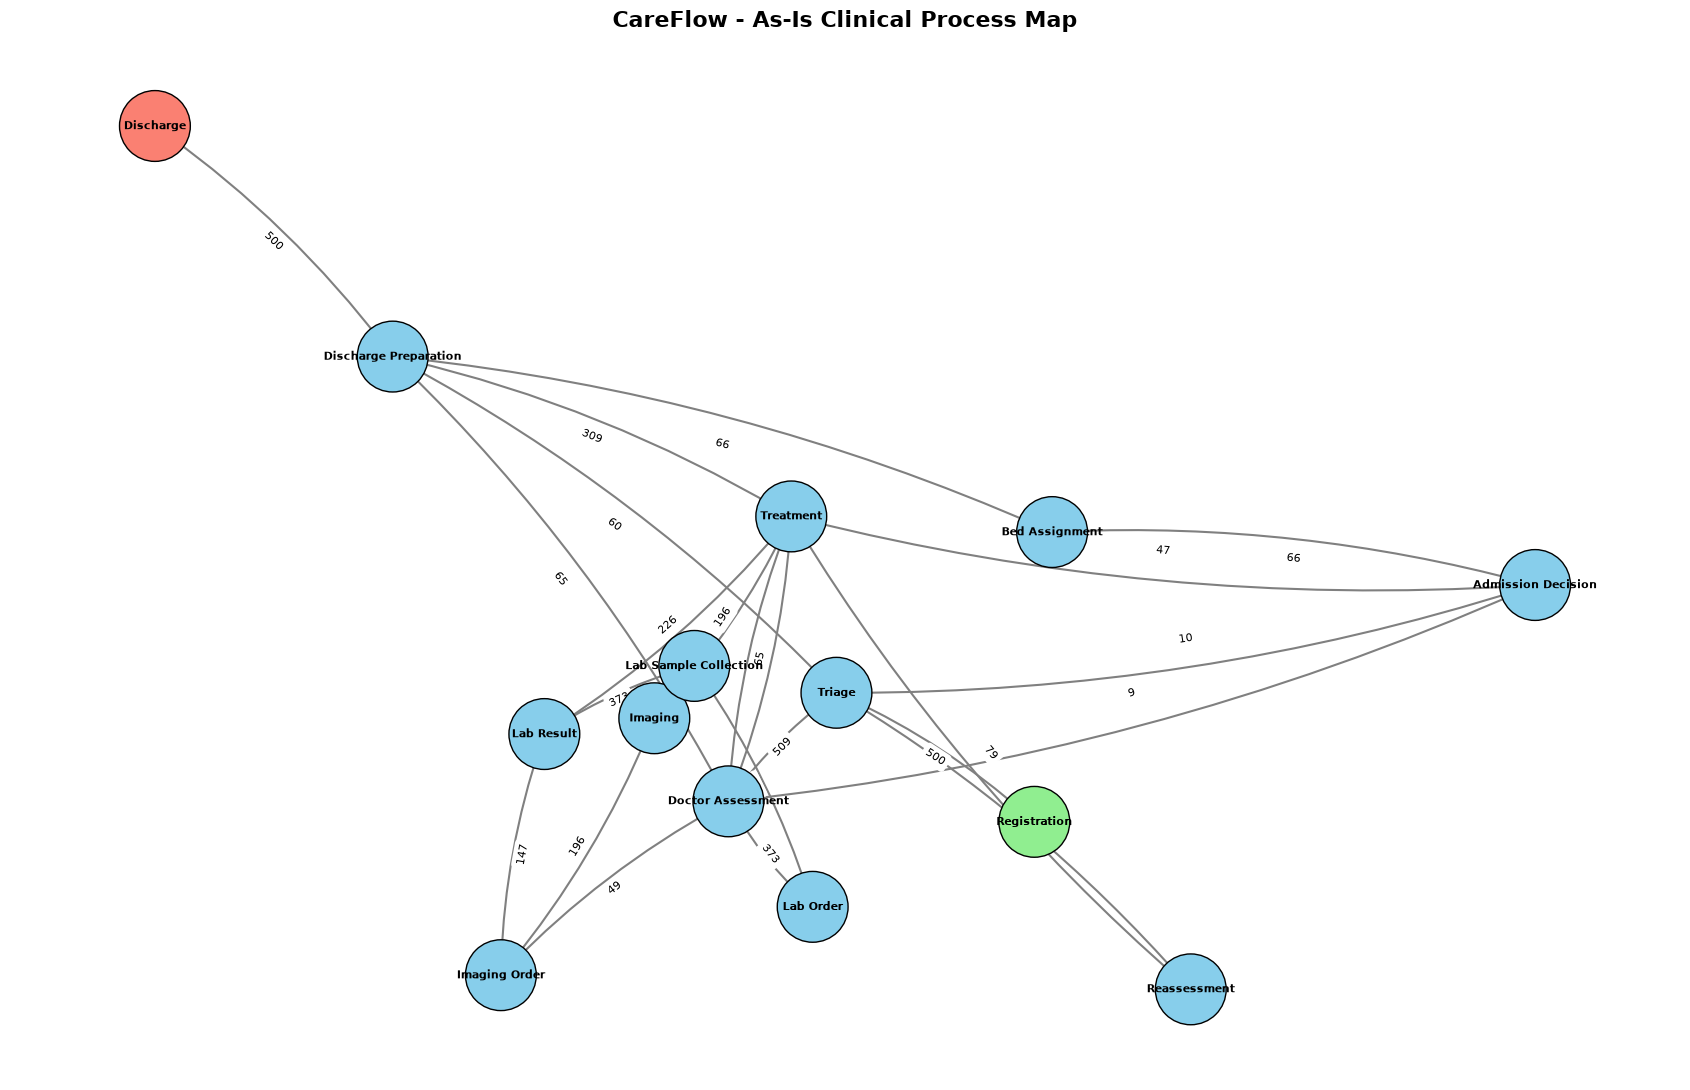

Process map saved: C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\outputs\careflow_as_is_process_map.png


In [31]:
import networkx as nx
import matplotlib.pyplot as plt

# Create directed process graph
G = nx.DiGraph()

# Add transitions and frequencies
for (source, target), frequency in dfg.items():
    G.add_edge(
        source,
        target,
        weight=frequency
    )

# Create figure
plt.figure(figsize=(17, 11))

# Layout
pos = nx.spring_layout(
    G,
    seed=42,
    k=1.5,
    iterations=150
)

# Identify start and end activities
start_nodes = list(start_activities.keys())
end_nodes = list(end_activities.keys())

node_colors = []

for node in G.nodes():
    if node in start_nodes:
        node_colors.append("lightgreen")
    elif node in end_nodes:
        node_colors.append("salmon")
    else:
        node_colors.append("skyblue")

# Draw nodes
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=2600,
    node_color=node_colors,
    edgecolors="black"
)

# Draw labels
nx.draw_networkx_labels(
    G,
    pos,
    font_size=8,
    font_weight="bold"
)

# Draw directed edges
nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=20,
    edge_color="gray",
    width=1.5,
    connectionstyle="arc3,rad=0.08"
)

# Add transition frequencies
edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title(
    "CareFlow - As-Is Clinical Process Map",
    fontsize=16,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()

# Save process map
process_map_path = (
    OUTPUT_DIR / "careflow_as_is_process_map.png"
)

plt.savefig(
    process_map_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Process map saved:", process_map_path)

# Export discovery results

In [32]:
# Export start activities
pd.DataFrame(
    start_activities.items(),
    columns=["activity", "frequency"]
).to_csv(
    OUTPUT_DIR / "careflow_start_activities.csv",
    index=False
)

# Export end activities
pd.DataFrame(
    end_activities.items(),
    columns=["activity", "frequency"]
).to_csv(
    OUTPUT_DIR / "careflow_end_activities.csv",
    index=False
)

# Export variants
variant_counts.to_csv(
    OUTPUT_DIR / "careflow_process_variants.csv",
    index=False
)

print("All process discovery artifacts exported.")

print("Transitions:", len(dfg))
print("Variants:", len(variant_counts))
print("Activities:", len(G.nodes))

All process discovery artifacts exported.
Transitions: 23
Variants: 25
Activities: 14


# Save discovery summary

In [33]:
import json

discovery_summary = {
    "total_events": int(len(event_log)),
    "total_cases": int(event_log["case:concept:name"].nunique()),
    "total_activities": int(len(G.nodes)),
    "total_transitions": int(len(dfg)),
    "total_variants": int(len(variant_counts)),
    "start_activities": start_activities,
    "end_activities": end_activities,
    "top_10_transitions": [
        {
            "source": str(source),
            "target": str(target),
            "frequency": int(freq)
        }
        for (source, target), freq in
        sorted(dfg.items(), key=lambda x: x[1], reverse=True)[:10]
    ]
}

report_path = OUTPUT_DIR / "week2_process_discovery_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(discovery_summary, f, indent=4)

print("Week 2 discovery report saved:", report_path)

Week 2 discovery report saved: C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining\outputs\week2_process_discovery_report.json


# Verify all output files

In [34]:
required_files = [
    "careflow_process_edges.csv",
    "careflow_process_variants.csv",
    "careflow_start_activities.csv",
    "careflow_end_activities.csv",
    "careflow_as_is_process_map.png",
    "week2_process_discovery_report.json"
]

for filename in required_files:
    path = OUTPUT_DIR / filename
    print(
        filename,
        "->",
        "FOUND" if path.exists() else "MISSING"
    )

careflow_process_edges.csv -> FOUND
careflow_process_variants.csv -> FOUND
careflow_start_activities.csv -> FOUND
careflow_end_activities.csv -> FOUND
careflow_as_is_process_map.png -> FOUND
week2_process_discovery_report.json -> FOUND
